In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
from PIL import Image

# CAMBIA ESTA RUTA por la carpeta principal del dataset
DATASET_DIR = "/content/drive/MyDrive/BASE DE DATOS ANDRAS"

extensiones = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

registros = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(extensiones):
            ruta = os.path.join(root, file)

            # Carpeta inmediata donde está la imagen
            clase = os.path.basename(root)

            try:
                with Image.open(ruta) as img:
                    ancho, alto = img.size
                    modo = img.mode
                    formato = img.format
            except Exception:
                ancho = None
                alto = None
                modo = None
                formato = None

            registros.append({
                "archivo": file,
                "clase": clase,
                "ruta_relativa": os.path.relpath(ruta, DATASET_DIR),
                "ancho": ancho,
                "alto": alto,
                "modo": modo,
                "formato": formato
            })

df_inventory = pd.DataFrame(registros)

print("Total de imágenes:", len(df_inventory))

print("\nImágenes por clase:")
print(df_inventory["clase"].value_counts().sort_index())

print("\nResoluciones más comunes:")
print(
    df_inventory.groupby(["ancho", "alto"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

print("\nFormatos:")
print(df_inventory["formato"].value_counts(dropna=False))

display(df_inventory.head(10))

df_inventory.to_csv(
    "/content/dataset_inventory.csv",
    index=False
)

print("\nInventario guardado en /content/dataset_inventory.csv")

KeyboardInterrupt: 

##Cargar directamente los splits

In [ ]:
import pandas as pd
import os

METADATA_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/metadata"

df_subset = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_dataset_subset.csv")
)

train_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_test_split.csv")
)

print("Subset:", len(df_subset))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Subset: 7571
Train: 6056
Validation: 757
Test: 758


In [ ]:
import os
from collections import Counter

extensiones = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

conteo = Counter()
total = 0

for root, dirs, files in os.walk(DATASET_DIR):
    imagenes = [
        f for f in files
        if f.lower().endswith(extensiones)
    ]

    if imagenes:
        clase = os.path.basename(root)
        conteo[clase] += len(imagenes)
        total += len(imagenes)

print("Total de imágenes:", total)

print("\nImágenes por carpeta/clase:")
for clase, cantidad in sorted(conteo.items()):
    print(f"{clase}: {cantidad}")

Total de imágenes: 92138

Imágenes por carpeta/clase:
S00: 829
S01: 1136
S02: 12440
S03: 5241
S04: 742
S05: 12565
S06: 12509
S07: 46494
S08: 33
S09: 56
S10: 54
S11: 39


In [ ]:
import os
import random
from PIL import Image
from collections import Counter

# Carpeta principal del dataset
# Ajusta esta ruta a la ubicación real en tu Google Drive
DATASET_DIR = "/content/drive/MyDrive/BASE DE DATOS ANDRAS"

# Clases que sí vamos a utilizar
CLASES = [f"S{i:02d}" for i in range(8)]

# Extensiones de imagen aceptadas
EXTENSIONES = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

archivos = []
conteo_clases = Counter()

# Recorrer el dataset
for root, dirs, files in os.walk(DATASET_DIR):

    clase = os.path.basename(root)

    # Ignorar S08, S09, S10, S11 y cualquier otra carpeta
    if clase not in CLASES:
        continue

    for file in files:
        if file.lower().endswith(EXTENSIONES):

            ruta = os.path.join(root, file)

            archivos.append(ruta)
            conteo_clases[clase] += 1


# Mostrar cantidad total de imágenes
print("Total de imágenes utilizadas:", len(archivos))

print("\nImágenes por clase:")
for clase in CLASES:
    print(f"{clase}: {conteo_clases[clase]}")


# ---------------------------------------------------------
# Revisar una muestra de imágenes para conocer resoluciones
# ---------------------------------------------------------

random.seed(42)

tamano_muestra = min(500, len(archivos))

muestra = random.sample(archivos, tamano_muestra)

resoluciones = Counter()
modos = Counter()
formatos = Counter()
errores = 0

for ruta in muestra:

    try:
        with Image.open(ruta) as img:

            resoluciones[img.size] += 1
            modos[img.mode] += 1
            formatos[img.format] += 1

    except Exception:
        errores += 1


# Mostrar resultados
print(f"\nImágenes revisadas en la muestra: {tamano_muestra}")

print("\nResoluciones encontradas:")
for resolucion, cantidad in resoluciones.most_common(20):
    print(f"{resolucion}: {cantidad}")


print("\nModos de imagen:")
for modo, cantidad in modos.items():
    print(f"{modo}: {cantidad}")


print("\nFormatos:")
for formato, cantidad in formatos.items():
    print(f"{formato}: {cantidad}")


print("\nErrores al abrir imágenes:", errores)

Total de imágenes utilizadas: 91956

Imágenes por clase:
S00: 829
S01: 1136
S02: 12440
S03: 5241
S04: 742
S05: 12565
S06: 12509
S07: 46494

Imágenes revisadas en la muestra: 500

Resoluciones encontradas:
(1440, 1080): 500

Modos de imagen:
RGB: 500

Formatos:
JPEG: 500

Errores al abrir imágenes: 0


In [ ]:
import os
import pandas as pd

# Clases que utilizaremos
CLASES = [f"S{i:02d}" for i in range(8)]

# Extensiones válidas
EXTENSIONES = ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')

registros = []

for root, dirs, files in os.walk(DATASET_DIR):

    clase = os.path.basename(root)

    if clase not in CLASES:
        continue

    label = CLASES.index(clase)

    for file in files:
        if file.lower().endswith(EXTENSIONES):

            registros.append({
                "filepath": os.path.join(root, file),
                "class_name": clase,
                "label": label
            })

df = pd.DataFrame(registros)

print("Total de imágenes:", len(df))

print("\nDistribución por clase:")
print(df["class_name"].value_counts().sort_index())

display(df.head())

Total de imágenes: 91956

Distribución por clase:
class_name
S00      829
S01     1136
S02    12440
S03     5241
S04      742
S05    12565
S06    12509
S07    46494
Name: count, dtype: int64


,filepath,class_name,label
0,/content/drive/MyDrive/BASE DE DATOS ANDRAS/S0...,S02,2
1,/content/drive/MyDrive/BASE DE DATOS ANDRAS/S0...,S02,2
2,/content/drive/MyDrive/BASE DE DATOS ANDRAS/S0...,S02,2
3,/content/drive/MyDrive/BASE DE DATOS ANDRAS/S0...,S02,2
4,/content/drive/MyDrive/BASE DE DATOS ANDRAS/S0...,S02,2


## 3. Controlled Dataset Subsampling

In [ ]:
import pandas as pd

SEED = 42
MAX_IMAGES_PER_CLASS = 1000

subset_parts = []

for clase in CLASES:

    class_df = df[df["class_name"] == clase]

    # Si la clase tiene más de 3000 imágenes,
    # seleccionar aleatoriamente 3000.
    if len(class_df) > MAX_IMAGES_PER_CLASS:
        class_df = class_df.sample(
            n=MAX_IMAGES_PER_CLASS,
            random_state=SEED
        )

    # Si tiene menos de 3000, conservar todas.
    subset_parts.append(class_df)

# Unir todas las clases
df_subset = pd.concat(
    subset_parts,
    ignore_index=True
)

# Mezclar el dataset completo
df_subset = df_subset.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

# Mostrar resultados
print("Dataset original:", len(df))
print("Dataset utilizado:", len(df_subset))

print("\nDistribución por clase:")
print(
    df_subset["class_name"]
    .value_counts()
    .sort_index()
)

print(
    f"\nPorcentaje del dataset completo utilizado: "
    f"{len(df_subset) / len(df) * 100:.2f}%"
)

Dataset original: 91956
Dataset utilizado: 7571

Distribución por clase:
class_name
S00     829
S01    1000
S02    1000
S03    1000
S04     742
S05    1000
S06    1000
S07    1000
Name: count, dtype: int64

Porcentaje del dataset completo utilizado: 8.23%


## 4. Stratified Train, Validation, and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# ---------------------------------------------------------
# Primera división:
# 80% entrenamiento
# 20% temporal
# ---------------------------------------------------------

train_df, temp_df = train_test_split(
    df_subset,
    test_size=0.20,
    random_state=SEED,
    stratify=df_subset["label"]
)

# ---------------------------------------------------------
# Segunda división:
# 10% validación
# 10% prueba
# ---------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Reiniciar índices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ---------------------------------------------------------
# Mostrar tamaños
# ---------------------------------------------------------

print("Total utilizado:", len(df_subset))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nPorcentajes:")
print(f"Training:   {len(train_df) / len(df_subset) * 100:.2f}%")
print(f"Validation: {len(val_df) / len(df_subset) * 100:.2f}%")
print(f"Test:       {len(test_df) / len(df_subset) * 100:.2f}%")

# ---------------------------------------------------------
# Distribución por clase
# ---------------------------------------------------------

split_distribution = pd.DataFrame({
    "Total": df_subset["class_name"].value_counts().sort_index(),
    "Train": train_df["class_name"].value_counts().sort_index(),
    "Validation": val_df["class_name"].value_counts().sort_index(),
    "Test": test_df["class_name"].value_counts().sort_index()
})

display(split_distribution)

# ---------------------------------------------------------
# Verificar que no existan imágenes repetidas entre subsets
# ---------------------------------------------------------

train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("\nOverlaps:")
print("Train / Validation:", len(train_paths.intersection(val_paths)))
print("Train / Test:", len(train_paths.intersection(test_paths)))
print("Validation / Test:", len(val_paths.intersection(test_paths)))

Total utilizado: 7571
Training: 6056
Validation: 757
Test: 758

Porcentajes:
Training:   79.99%
Validation: 10.00%
Test:       10.01%


,Total,Train,Validation,Test
class_name,,,,
S00,829,663,83,83
S01,1000,800,100,100
S02,1000,800,100,100
S03,1000,800,100,100
S04,742,593,74,75
S05,1000,800,100,100
S06,1000,800,100,100
S07,1000,800,100,100



Overlaps:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


## 5. Save Dataset Subset and Splits

In [ ]:
import os

# Carpeta donde guardaremos la información del Deliverable 2
METADATA_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/metadata"

os.makedirs(METADATA_DIR, exist_ok=True)

# Guardar dataset seleccionado y splits
df_subset.to_csv(
    os.path.join(METADATA_DIR, "cnn_dataset_subset.csv"),
    index=False
)

train_df.to_csv(
    os.path.join(METADATA_DIR, "cnn_train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(METADATA_DIR, "cnn_validation_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(METADATA_DIR, "cnn_test_split.csv"),
    index=False
)

print("Archivos guardados correctamente en:")
print(METADATA_DIR)

print("\nArchivos:")
for file in os.listdir(METADATA_DIR):
    print("-", file)

Archivos guardados correctamente en:
/content/drive/MyDrive/CNN_DELIVERABLE2/metadata

Archivos:
- cnn_dataset_subset.csv
- cnn_train_split.csv
- cnn_validation_split.csv
- cnn_test_split.csv


## 6. Compute Class Weights

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Etiquetas del conjunto de entrenamiento
y_train = train_df["label"].values

# Clases disponibles
classes = np.unique(y_train)

# Calcular pesos balanceados usando SOLO training
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convertir a diccionario para TensorFlow/Keras
class_weights = {
    int(clase): float(peso)
    for clase, peso in zip(classes, weights)
}

print("Class weights:")

for clase, peso in class_weights.items():
    print(f"{CLASES[clase]} ({clase}): {peso:.4f}")

Class weights:
S00 (0): 1.1418
S01 (1): 0.9463
S02 (2): 0.9463
S03 (3): 0.9463
S04 (4): 1.2766
S05 (5): 0.9463
S06 (6): 0.9463
S07 (7): 0.9463


## 7. Image Preprocessing Configuration

In [ ]:
import tensorflow as tf

# ---------------------------------------------------------
# Configuración general
# ---------------------------------------------------------

IMG_HEIGHT = 224
IMG_WIDTH = 224
CHANNELS = 3
BATCH_SIZE = 32

AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("Image size:", (IMG_HEIGHT, IMG_WIDTH, CHANNELS))
print("Batch size:", BATCH_SIZE)

# Verificar disponibilidad de GPU
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU detected:", gpus[0])
else:
    print("No GPU detected. Training will use CPU.")

TensorFlow version: 2.21.0
Image size: (224, 224, 3)
Batch size: 32
GPU detected: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


## 8. Image Loading and Preprocessing Functions

In [ ]:
# ---------------------------------------------------------
# Función para cargar una imagen desde su ruta
# ---------------------------------------------------------

def load_image(image_path):
    # Leer archivo
    image = tf.io.read_file(image_path)

    # Decodificar JPEG como imagen RGB
    image = tf.image.decode_jpeg(
        image,
        channels=CHANNELS
    )

    # Convertir a float32 y normalizar al rango [0, 1]
    image = tf.image.convert_image_dtype(
        image,
        tf.float32
    )

    return image


# ---------------------------------------------------------
# Preprocesamiento para TRAINING
# Random crop de 224 x 224
# ---------------------------------------------------------

def preprocess_train(image_path, label):
    image = load_image(image_path)

    image = tf.image.random_crop(
        image,
        size=[IMG_HEIGHT, IMG_WIDTH, CHANNELS]
    )

    return image, label


# ---------------------------------------------------------
# Preprocesamiento para VALIDATION y TEST
# Center crop de 224 x 224
# ---------------------------------------------------------

def preprocess_eval(image_path, label):
    image = load_image(image_path)

    # Obtener dimensiones actuales
    shape = tf.shape(image)

    height = shape[0]
    width = shape[1]

    # Coordenadas para crop central
    offset_height = (height - IMG_HEIGHT) // 2
    offset_width = (width - IMG_WIDTH) // 2

    image = tf.image.crop_to_bounding_box(
        image,
        offset_height,
        offset_width,
        IMG_HEIGHT,
        IMG_WIDTH
    )

    return image, label

## 9. Build TensorFlow Datasets

In [ ]:
# ---------------------------------------------------------
# Obtener rutas y etiquetas de cada split
# ---------------------------------------------------------

train_paths = train_df["filepath"].astype(str).values
train_labels = train_df["label"].astype("int32").values

val_paths = val_df["filepath"].astype(str).values
val_labels = val_df["label"].astype("int32").values

test_paths = test_df["filepath"].astype(str).values
test_labels = test_df["label"].astype("int32").values


# ---------------------------------------------------------
# Crear datasets a partir de rutas y etiquetas
# ---------------------------------------------------------

train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)


# ---------------------------------------------------------
# TRAINING
# Shuffle -> preprocessing -> batch -> prefetch
# ---------------------------------------------------------

train_dataset = (
    train_dataset
    .shuffle(
        buffer_size=len(train_df),
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .map(
        preprocess_train,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ---------------------------------------------------------
# VALIDATION
# Sin shuffle y con center crop
# ---------------------------------------------------------

val_dataset = (
    val_dataset
    .map(
        preprocess_eval,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ---------------------------------------------------------
# TEST
# Sin shuffle y con center crop
# ---------------------------------------------------------

test_dataset = (
    test_dataset
    .map(
        preprocess_eval,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)


# ---------------------------------------------------------
# Información general
# ---------------------------------------------------------

print("TensorFlow datasets created successfully.")

print("\nNumber of images:")
print("Training:  ", len(train_df))
print("Validation:", len(val_df))
print("Test:      ", len(test_df))

print("\nNumber of batches:")
print("Training:  ", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:      ", len(test_dataset))

TensorFlow datasets created successfully.

Number of images:
Training:   6056
Validation: 757
Test:       758

Number of batches:
Training:   190
Validation: 24
Test:       24


## 10. Verify Dataset Batches

In [ ]:
# ---------------------------------------------------------
# Tomar un batch del conjunto de entrenamiento
# ---------------------------------------------------------

for images, labels in train_dataset.take(1):

    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

    print("\nImage dtype:", images.dtype)
    print("Labels dtype:", labels.dtype)

    print("\nMinimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("\nFirst labels in batch:")
    print(labels[:10].numpy())

Images shape: (32, 224, 224, 3)
Labels shape: (32,)

Image dtype: <dtype: 'float32'>
Labels dtype: <dtype: 'int32'>

Minimum pixel value: 0.0
Maximum pixel value: 1.0

First labels in batch:
[3 5 6 3 1 6 5 4 6 1]


## 11. Visualize Processed Training Samples

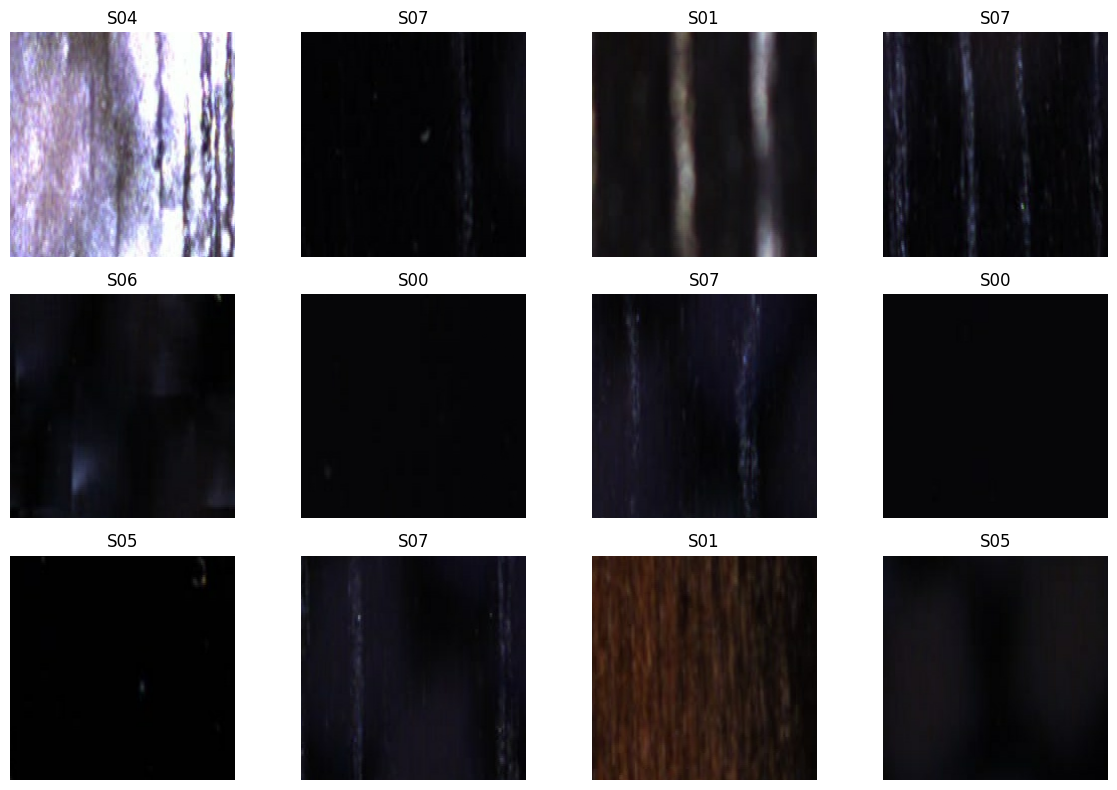

In [ ]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Tomar un batch del conjunto de entrenamiento
# ---------------------------------------------------------

for images, labels in train_dataset.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy())

        label_index = int(labels[i].numpy())
        plt.title(CLASES[label_index])

        plt.axis("off")

    plt.tight_layout()
    plt.show()

## 12. Data Augmentation

In [ ]:
# ---------------------------------------------------------
# Data augmentation
# Misma configuración utilizada en CNN-B01
# ---------------------------------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        "horizontal_and_vertical"
    ),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation configured successfully.")

Data augmentation configured successfully.


## 13. CNN-B02 Baseline Architecture

In [ ]:
from tensorflow.keras import layers, models

# ---------------------------------------------------------
# Definición del modelo CNN-B02
# ---------------------------------------------------------

model = models.Sequential([

    # Entrada
    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    ),

    # Data augmentation
    data_augmentation,

    # -----------------------------------------------------
    # Bloque convolucional 1
    # -----------------------------------------------------
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # -----------------------------------------------------
    # Bloque convolucional 2
    # -----------------------------------------------------
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # -----------------------------------------------------
    # Bloque convolucional 3
    # -----------------------------------------------------
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # -----------------------------------------------------
    # Clasificador
    # -----------------------------------------------------
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.30),

    layers.Dense(
        len(CLASES),
        activation="softmax"
    )
])


# ---------------------------------------------------------
# Mostrar arquitectura
# ---------------------------------------------------------

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,688 (436.28 KB)

 Trainable params: 111,240 (434.53 KB)

 Non-trainable params: 448 (1.75 KB)

## 14. Compile CNN-B02

In [ ]:
# ---------------------------------------------------------
# Configuración del optimizador
# ---------------------------------------------------------

INITIAL_LR = 0.001

optimizer = tf.keras.optimizers.Adam(
    learning_rate=INITIAL_LR
)

# ---------------------------------------------------------
# Compilar modelo
# ---------------------------------------------------------

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN-B02 compiled successfully.")
print("Optimizer: Adam")
print("Initial learning rate:", INITIAL_LR)
print("Loss: sparse_categorical_crossentropy")

CNN-B02 compiled successfully.
Optimizer: Adam
Initial learning rate: 0.001
Loss: sparse_categorical_crossentropy


## 15. Training Callbacks

In [ ]:
# ---------------------------------------------------------
# Configuración general del entrenamiento
# ---------------------------------------------------------

MAX_EPOCHS = 20

# ---------------------------------------------------------
# Early Stopping
# ---------------------------------------------------------

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# ---------------------------------------------------------
# Reduce Learning Rate on Plateau
# ---------------------------------------------------------

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# ---------------------------------------------------------
# Lista de callbacks
# ---------------------------------------------------------

callbacks = [
    early_stopping,
    reduce_lr
]

print("Training callbacks configured successfully.")
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", 5)
print("LR reduction factor:", 0.5)
print("LR reduction patience:", 2)
print("Minimum learning rate:", 1e-6)

Training callbacks configured successfully.
Maximum epochs: 20
Early stopping patience: 5
LR reduction factor: 0.5
LR reduction patience: 2
Minimum learning rate: 1e-06


## 16. Train CNN-B02

In [ ]:
# ---------------------------------------------------------
# Entrenamiento del modelo CNN-B02
# ---------------------------------------------------------

history_B02 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=MAX_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 1155s 6s/step - accuracy: 0.7015 - loss: 0.7818 - val_accuracy: 0.1506 - val_loss: 2.2925 - learning_rate: 0.0010
Epoch 2/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 372ms/step - accuracy: 0.8469 - loss: 0.4171 - val_accuracy: 0.2378 - val_loss: 2.5418 - learning_rate: 0.0010
Epoch 3/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 97s 452ms/step - accuracy: 0.8826 - loss: 0.3352 - val_accuracy: 0.4650 - val_loss: 1.8140 - learning_rate: 0.0010
Epoch 4/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 73s 381ms/step - accuracy: 0.9097 - loss: 0.2772 - val_accuracy: 0.6433 - val_loss: 1.8850 - learning_rate: 0.0010
Epoch 5/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 81s 378ms/step - accuracy: 0.9186 - loss: 0.2441 - val_accuracy: 0.6803 - val_loss: 1.5128 - learning_rate: 0.0010
Epoch 6/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 79s 363ms/step - accuracy: 0.9278 - loss: 0.2117 - val_accuracy: 0.8507 - val_loss: 0.4362 - learning_rate: 0.0010
Epoch 7/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 86s 381ms/step - accuracy: 0.93

## 17. Save CNN-B02 Model and Training History

In [ ]:
import os
import pandas as pd

# ---------------------------------------------------------
# Carpeta para guardar CNN-B02
# ---------------------------------------------------------

MODEL_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/models"
os.makedirs(MODEL_DIR, exist_ok=True)

# ---------------------------------------------------------
# Guardar modelo completo
# ---------------------------------------------------------

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CNN_B02.keras"
)

model.save(MODEL_PATH)

# ---------------------------------------------------------
# Guardar historial de entrenamiento
# ---------------------------------------------------------

history_df = pd.DataFrame(history_B02.history)

HISTORY_PATH = os.path.join(
    MODEL_DIR,
    "CNN_B02_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

# ---------------------------------------------------------
# Confirmación
# ---------------------------------------------------------

print("CNN-B02 saved successfully.")

print("\nModel:")
print(MODEL_PATH)

print("\nTraining history:")
print(HISTORY_PATH)

CNN-B02 saved successfully.

Model:
/content/drive/MyDrive/CNN_DELIVERABLE2/models/CNN_B02.keras

Training history:
/content/drive/MyDrive/CNN_DELIVERABLE2/models/CNN_B02_history.csv


## 18. CNN-B02 Training Summary

In [ ]:
train_loss = history_B02.history["loss"]
val_loss = history_B02.history["val_loss"]

train_accuracy = history_B02.history["accuracy"]
val_accuracy = history_B02.history["val_accuracy"]

# Mejor época según validation loss
best_epoch = np.argmin(val_loss) + 1

print("CNN-B02 Training Summary")
print("------------------------")

print("Epochs trained:", len(train_loss))
print("Best epoch:", best_epoch)

print("\nBest epoch results:")
print(f"Training accuracy:   {train_accuracy[best_epoch - 1]:.4f}")
print(f"Training loss:       {train_loss[best_epoch - 1]:.4f}")
print(f"Validation accuracy: {val_accuracy[best_epoch - 1]:.4f}")
print(f"Validation loss:     {val_loss[best_epoch - 1]:.4f}")

print("\nHighest validation accuracy:")
print(
    f"{max(val_accuracy):.4f} "
    f"(Epoch {np.argmax(val_accuracy) + 1})"
)

CNN-B02 Training Summary
------------------------
Epochs trained: 20
Best epoch: 19

Best epoch results:
Training accuracy:   0.9690
Training loss:       0.1014
Validation accuracy: 0.9828
Validation loss:     0.0486

Highest validation accuracy:
0.9828 (Epoch 18)


## 19. CNN-B02 Training Curves

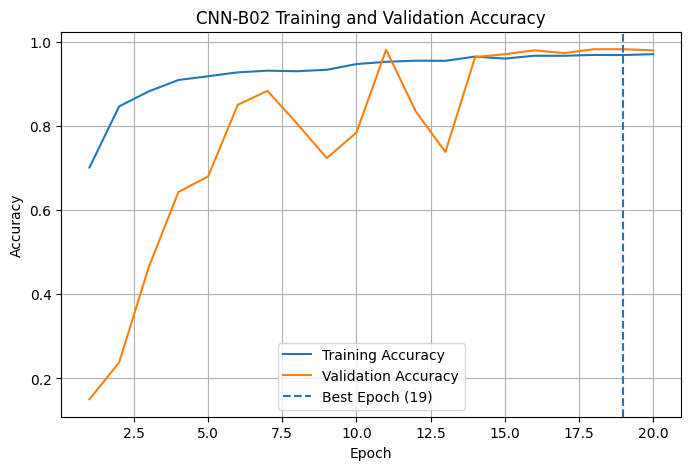

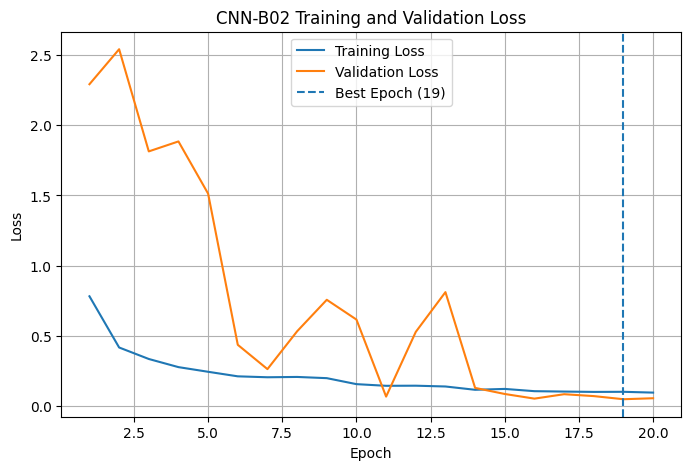

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history_B02.history["loss"]) + 1)

# ---------------------------------------------------------
# Accuracy
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history_B02.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_B02.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN-B02 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Loss
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history_B02.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_B02.history["val_loss"],
    label="Validation Loss"
)

plt.axvline(
    x=best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-B02 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

## 20. CNN-B02 Test Evaluation

In [ ]:
from sklearn.metrics import f1_score, classification_report
import numpy as np

# ---------------------------------------------------------
# Evaluar modelo en el conjunto de prueba
# ---------------------------------------------------------

test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

# ---------------------------------------------------------
# Obtener predicciones
# ---------------------------------------------------------

y_prob = model.predict(
    test_dataset,
    verbose=1
)

y_pred = np.argmax(
    y_prob,
    axis=1
)

# Etiquetas reales
y_true = test_labels

# ---------------------------------------------------------
# Macro F1-score
# ---------------------------------------------------------

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

# ---------------------------------------------------------
# Resultados generales
# ---------------------------------------------------------

print("\nCNN-B02 Test Results")
print("--------------------")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Macro F1:      {macro_f1:.4f}")

# ---------------------------------------------------------
# Classification report
# ---------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASES,
        digits=4
    )
)

24/24 ━━━━━━━━━━━━━━━━━━━━ 177s 7s/step - accuracy: 0.9868 - loss: 0.0556
24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 294ms/step

CNN-B02 Test Results
--------------------
Test Accuracy: 0.9868
Test Loss:     0.0556
Macro F1:      0.9871

Classification Report:
              precision    recall  f1-score   support

         S00     0.9878    0.9759    0.9818        83
         S01     0.9898    0.9700    0.9798       100
         S02     0.9901    1.0000    0.9950       100
         S03     0.9703    0.9800    0.9751       100
         S04     1.0000    1.0000    1.0000        75
         S05     0.9802    0.9900    0.9851       100
         S06     0.9901    1.0000    0.9950       100
         S07     0.9899    0.9800    0.9849       100

    accuracy                         0.9868       758
   macro avg     0.9873    0.9870    0.9871       758
weighted avg     0.9868    0.9868    0.9868       758



## 21. CNN-B02 Normalized Confusion Matrix

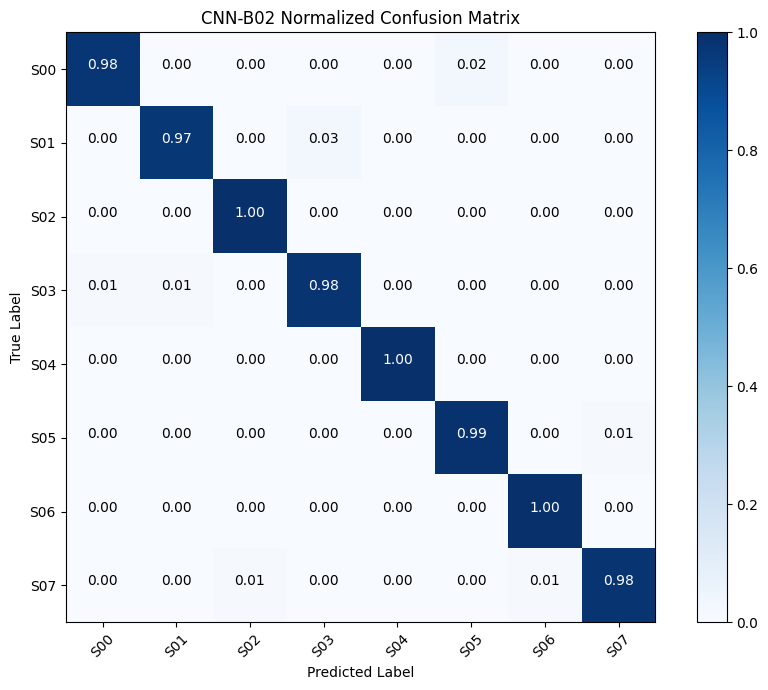

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# Matriz de confusión
# ---------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

# ---------------------------------------------------------
# Normalización por clase real
# ---------------------------------------------------------

cm_normalized = cm.astype("float") / cm.sum(
    axis=1,
    keepdims=True
)

# ---------------------------------------------------------
# Visualización
# ---------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.imshow(
    cm_normalized,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("CNN-B02 Normalized Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(CLASES))

plt.xticks(
    tick_marks,
    CLASES,
    rotation=45
)

plt.yticks(
    tick_marks,
    CLASES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# ---------------------------------------------------------
# Valores dentro de cada celda
# ---------------------------------------------------------

threshold = cm_normalized.max() / 2

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):

        plt.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            horizontalalignment="center",
            color="white" if cm_normalized[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

## 22. Save CNN-B02 Evaluation Results

In [ ]:
# ---------------------------------------------------------
# Crear carpeta de resultados
# ---------------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/results"

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ---------------------------------------------------------
# Resumen general del experimento
# ---------------------------------------------------------

experiment_results = pd.DataFrame([{
    "experiment": "CNN-B02",
    "dataset_size": len(df_subset),
    "train_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "batch_size": BATCH_SIZE,
    "initial_learning_rate": INITIAL_LR,
    "max_epochs": MAX_EPOCHS,
    "epochs_trained": len(history_B02.history["loss"]),
    "best_epoch": best_epoch,
    "best_val_accuracy": val_accuracy[best_epoch - 1],
    "best_val_loss": val_loss[best_epoch - 1],
    "test_accuracy": test_accuracy,
    "test_loss": test_loss,
    "macro_f1": macro_f1
}])

# ---------------------------------------------------------
# Guardar resumen general
# ---------------------------------------------------------

experiment_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "CNN_B02_results.csv"
    ),
    index=False
)

# ---------------------------------------------------------
# Classification report como DataFrame
# ---------------------------------------------------------

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=CLASES,
    output_dict=True
)

report_df = pd.DataFrame(
    report_dict
).transpose()

report_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "CNN_B02_classification_report.csv"
    )
)

# ---------------------------------------------------------
# Guardar matriz de confusión numérica
# ---------------------------------------------------------

cm_df = pd.DataFrame(
    cm,
    index=CLASES,
    columns=CLASES
)

cm_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "CNN_B02_confusion_matrix.csv"
    )
)

# ---------------------------------------------------------
# Mostrar resumen
# ---------------------------------------------------------

print("CNN-B02 results saved successfully.")

print("\nExperiment summary:")
display(experiment_results)

print("\nFiles saved in:")
print(RESULTS_DIR)

CNN-B02 results saved successfully.

Experiment summary:


,experiment,dataset_size,train_images,validation_images,test_images,batch_size,initial_learning_rate,max_epochs,epochs_trained,best_epoch,best_val_accuracy,best_val_loss,test_accuracy,test_loss,macro_f1
0,CNN-B02,7571,6056,757,758,32,0.001,20,20,19,0.982827,0.048612,0.986807,0.055644,0.987099



Files saved in:
/content/drive/MyDrive/CNN_DELIVERABLE2/results


## 23. CNN-D03 - Extended Training Experiment

In [ ]:
# ---------------------------------------------------------
# Construir CNN-D03 desde cero
# Misma arquitectura que CNN-B02
# ---------------------------------------------------------

model_D03 = models.Sequential([

    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    ),

    data_augmentation,

    # Bloque convolucional 1
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Bloque convolucional 2
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Bloque convolucional 3
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Clasificador
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.30),

    layers.Dense(
        len(CLASES),
        activation="softmax"
    )
])

# ---------------------------------------------------------
# Compilar
# ---------------------------------------------------------

model_D03.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN-D03 created successfully.")
print("Maximum epochs: 40")

model_D03.summary()

CNN-D03 created successfully.
Maximum epochs: 40


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,688 (436.28 KB)

 Trainable params: 111,240 (434.53 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# ---------------------------------------------------------
# CNN-D03 callbacks
# ---------------------------------------------------------

D03_MAX_EPOCHS = 40

early_stopping_D03 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D03 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D03 = [
    early_stopping_D03,
    reduce_lr_D03
]

print("CNN-D03 callbacks configured.")
print("Maximum epochs:", D03_MAX_EPOCHS)

CNN-D03 callbacks configured.
Maximum epochs: 40


In [ ]:
history_D03 = model_D03.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=D03_MAX_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_D03,
    verbose=1
)

Epoch 1/40
190/190 ━━━━━━━━━━━━━━━━━━━━ 73s 365ms/step - accuracy: 0.6868 - loss: 0.8159 - val_accuracy: 0.1096 - val_loss: 2.9073 - learning_rate: 0.0010
Epoch 2/40
190/190 ━━━━━━━━━━━━━━━━━━━━ 86s 389ms/step - accuracy: 0.8463 - loss: 0.4209 - val_accuracy: 0.1427 - val_loss: 4.2960 - learning_rate: 0.0010
Epoch 3/40
190/190 ━━━━━━━━━━━━━━━━━━━━ 68s 355ms/step - accuracy: 0.8694 - loss: 0.3669 - val_accuracy: 0.5033 - val_loss: 1.5613 - learning_rate: 0.0010
Epoch 4/40
190/190 ━━━━━━━━━━━━━━━━━━━━ 69s 361ms/step - accuracy: 0.9022 - loss: 0.2967 - val_accuracy: 0.9524 - val_loss: 0.1632 - learning_rate: 0.0010
Epoch 5/40
190/190 ━━━━━━━━━━━━━━━━━━━━ 83s 369ms/step - accuracy: 0.9166 - loss: 0.2534 - val_accuracy: 0.9498 - val_loss: 0.1754 - learning_rate: 0.0010
Epoch 6/40
189/190 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step - accuracy: 0.9154 - loss: 0.2524
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
190/190 ━━━━━━━━━━━━━━━━━━━━ 67s 350ms/step - accuracy: 0.920

## 26. Save CNN-D03 Results

In [ ]:
# ---------------------------------------------------------
# Obtener resultados de validación de CNN-D03
# ---------------------------------------------------------

d03_train_loss = history_D03.history["loss"]
d03_val_loss = history_D03.history["val_loss"]

d03_train_accuracy = history_D03.history["accuracy"]
d03_val_accuracy = history_D03.history["val_accuracy"]

d03_best_epoch = np.argmin(d03_val_loss) + 1

d03_best_val_loss = d03_val_loss[d03_best_epoch - 1]
d03_best_val_accuracy = d03_val_accuracy[d03_best_epoch - 1]

# ---------------------------------------------------------
# Resumen
# ---------------------------------------------------------

print("CNN-D03 Training Summary")
print("------------------------")

print("Epochs trained:", len(d03_train_loss))
print("Best epoch:", d03_best_epoch)

print("\nBest epoch results:")
print(f"Training accuracy:   {d03_train_accuracy[d03_best_epoch - 1]:.4f}")
print(f"Training loss:       {d03_train_loss[d03_best_epoch - 1]:.4f}")
print(f"Validation accuracy: {d03_best_val_accuracy:.4f}")
print(f"Validation loss:     {d03_best_val_loss:.4f}")

CNN-D03 Training Summary
------------------------
Epochs trained: 9
Best epoch: 4

Best epoch results:
Training accuracy:   0.9022
Training loss:       0.2967
Validation accuracy: 0.9524
Validation loss:     0.1632


## 27. CNN-D04 - Reduced Initial Learning Rate

In [ ]:
# ---------------------------------------------------------
# Construir CNN-D04 desde cero
# Único cambio respecto a CNN-B02:
# learning rate inicial = 0.0005
# ---------------------------------------------------------

model_D04 = models.Sequential([

    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    ),

    data_augmentation,

    # Bloque convolucional 1
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Bloque convolucional 2
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Bloque convolucional 3
    layers.Conv2D(
        128,
        kernel_size=(3, 3),
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Clasificador
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.30),

    layers.Dense(
        len(CLASES),
        activation="softmax"
    )
])

# ---------------------------------------------------------
# Compilar
# ---------------------------------------------------------

D04_INITIAL_LR = 0.0005

model_D04.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=D04_INITIAL_LR
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN-D04 created successfully.")
print("Initial learning rate:", D04_INITIAL_LR)
print("Maximum epochs: 20")

model_D04.summary()

CNN-D04 created successfully.
Initial learning rate: 0.0005
Maximum epochs: 20


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,688 (436.28 KB)

 Trainable params: 111,240 (434.53 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# ---------------------------------------------------------
# CNN-D04 callbacks
# ---------------------------------------------------------

D04_MAX_EPOCHS = 20

early_stopping_D04 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D04 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D04 = [
    early_stopping_D04,
    reduce_lr_D04
]

print("CNN-D04 callbacks configured.")
print("Maximum epochs:", D04_MAX_EPOCHS)
print("Initial learning rate:", D04_INITIAL_LR)

CNN-D04 callbacks configured.
Maximum epochs: 20
Initial learning rate: 0.0005


In [ ]:
history_D04 = model_D04.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=D04_MAX_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_D04,
    verbose=1
)

Epoch 1/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 78s 386ms/step - accuracy: 0.7155 - loss: 0.7908 - val_accuracy: 0.1096 - val_loss: 2.4227 - learning_rate: 5.0000e-04
Epoch 2/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 372ms/step - accuracy: 0.8641 - loss: 0.4023 - val_accuracy: 0.2153 - val_loss: 2.9322 - learning_rate: 5.0000e-04
Epoch 3/20
189/190 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.8885 - loss: 0.3288
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
190/190 ━━━━━━━━━━━━━━━━━━━━ 69s 361ms/step - accuracy: 0.8874 - loss: 0.3395 - val_accuracy: 0.4333 - val_loss: 2.9619 - learning_rate: 5.0000e-04
Epoch 4/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 373ms/step - accuracy: 0.9178 - loss: 0.2495 - val_accuracy: 0.7279 - val_loss: 0.5611 - learning_rate: 2.5000e-04
Epoch 5/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 83s 378ms/step - accuracy: 0.9268 - loss: 0.2295 - val_accuracy: 0.9234 - val_loss: 0.1919 - learning_rate: 2.5000e-04
Epoch 6/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 372ms/st

In [ ]:
# ---------------------------------------------------------
# Guardar modelo CNN-D04
# ---------------------------------------------------------

D04_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CNN_D04.keras"
)

model_D04.save(D04_MODEL_PATH)

# Guardar historial
pd.DataFrame(history_D04.history).to_csv(
    os.path.join(
        MODEL_DIR,
        "CNN_D04_history.csv"
    ),
    index=False
)

print("CNN-D04 saved successfully.")
print(D04_MODEL_PATH)

CNN-D04 saved successfully.
/content/drive/MyDrive/CNN_DELIVERABLE2/models/CNN_D04.keras


In [ ]:
# ---------------------------------------------------------
# CNN-D04 Test Evaluation
# ---------------------------------------------------------

d04_test_loss, d04_test_accuracy = model_D04.evaluate(
    test_dataset,
    verbose=1
)

d04_prob = model_D04.predict(
    test_dataset,
    verbose=1
)

d04_pred = np.argmax(
    d04_prob,
    axis=1
)

d04_macro_f1 = f1_score(
    test_labels,
    d04_pred,
    average="macro"
)

print("\nCNN-D04 Test Results")
print("--------------------")
print(f"Test Accuracy: {d04_test_accuracy:.4f}")
print(f"Test Loss:     {d04_test_loss:.4f}")
print(f"Macro F1:      {d04_macro_f1:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 382ms/step - accuracy: 0.9868 - loss: 0.0565
24/24 ━━━━━━━━━━━━━━━━━━━━ 8s 348ms/step

CNN-D04 Test Results
--------------------
Test Accuracy: 0.9868
Test Loss:     0.0565
Macro F1:      0.9873


##30.Evaluación de CNN-D03

In [ ]:
# ---------------------------------------------------------
# CNN-D03 Test Evaluation
# ---------------------------------------------------------

d03_test_loss, d03_test_accuracy = model_D03.evaluate(
    test_dataset,
    verbose=1
)

d03_prob = model_D03.predict(
    test_dataset,
    verbose=1
)

d03_pred = np.argmax(
    d03_prob,
    axis=1
)

d03_macro_f1 = f1_score(
    test_labels,
    d03_pred,
    average="macro"
)

print("\nCNN-D03 Test Results")
print("--------------------")
print(f"Test Accuracy: {d03_test_accuracy:.4f}")
print(f"Test Loss:     {d03_test_loss:.4f}")
print(f"Macro F1:      {d03_macro_f1:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 424ms/step - accuracy: 0.9472 - loss: 0.1765
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 296ms/step

CNN-D03 Test Results
--------------------
Test Accuracy: 0.9472
Test Loss:     0.1765
Macro F1:      0.9447


##31. CNN-D05

In [ ]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model_D05 = models.Sequential([

    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
    ),

    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    # Cambio experimental
    layers.Dropout(0.50),

    layers.Dense(
        8,
        activation="softmax"
    )
])

model_D05.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN-D05 rebuilt successfully.")

CNN-D05 rebuilt successfully.


In [ ]:
D05_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CNN_D05.keras"
)

checkpoint_D05 = tf.keras.callbacks.ModelCheckpoint(
    filepath=D05_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_D05 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_D05 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks_D05 = [
    checkpoint_D05,
    early_stopping_D05,
    reduce_lr_D05
]

In [ ]:
history_D05 = model_D05.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    class_weight=class_weights,
    callbacks=callbacks_D05,
    verbose=1
)

Epoch 1/20
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5637 - loss: 1.1736
Epoch 1: val_loss improved from None to 2.30538, saving model to /content/drive/MyDrive/CNN_DELIVERABLE2/models/CNN_D05.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CNN_DELIVERABLE2/models/CNN_D05.keras
190/190 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.6731 - loss: 0.8801 - val_accuracy: 0.2272 - val_loss: 2.3054 - learning_rate: 0.0010
Epoch 2/20
189/190 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.8095 - loss: 0.5268
Epoch 2: val_loss did not improve from 2.30538
190/190 ━━━━━━━━━━━━━━━━━━━━ 71s 373ms/step - accuracy: 0.8222 - loss: 0.4954 - val_accuracy: 0.2272 - val_loss: 3.0979 - learning_rate: 0.0010
Epoch 3/20
189/190 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.8543 - loss: 0.4196
Epoch 3: val_loss did not improve from 2.30538

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
190/190 ━━━━━━━━━━━━━━━━━━━━ 81s 368ms/step - accuracy: 0.86

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score

METADATA_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/metadata"
MODEL_DIR = "/content/drive/MyDrive/CNN_DELIVERABLE2/models"

train_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(METADATA_DIR, "cnn_test_split.csv")
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 6056
Validation: 757
Test: 758


In [ ]:
d05_test_loss, d05_test_accuracy = model_D05.evaluate(
    test_dataset,
    verbose=1
)

d05_prob = model_D05.predict(
    test_dataset,
    verbose=1
)

d05_pred = np.argmax(
    d05_prob,
    axis=1
)

d05_macro_f1 = f1_score(
    test_labels,
    d05_pred,
    average="macro"
)

print("\nCNN-D05 Test Results")
print("--------------------")
print(f"Test Accuracy: {d05_test_accuracy:.4f}")
print(f"Test Loss:     {d05_test_loss:.4f}")
print(f"Macro F1:      {d05_macro_f1:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.9855 - loss: 0.0816
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 298ms/step

CNN-D05 Test Results
--------------------
Test Accuracy: 0.9855
Test Loss:     0.0816
Macro F1:      0.9855
